# Phase 1 with different losses, side by side

The Phase 1 method (no neural network): optimize each scene's accelerations directly by backpropagating through the simulator, once per formation loss. Same scene, same start, same physics, same collision penalty; only the formation loss changes. One goal slot per drone, geometric shapes from the v3 benchmark.

| Loss | Pulls each drone toward |
|---|---|
| chamfer | its nearest slot (and each slot pulls its nearest drone); no one-to-one rule |
| matching | its own slot, from a Hungarian matching on the final frame |
| sinkhorn | a soft share of the slots (entropic optimal transport) |
| energy | all slots, while pushing away from other drones (energy distance / MMD) |
| laplacian | its own slot (matching) + the right shape of the whole formation (Quan et al.) |
| assigned | its own slot, assigned once from the start positions: the centralized reference |

The shape is scored over the last 20% of steps, as in policy training. Code: `swarm/formation_losses.py`; settings: `swarm/experiments.py`. About 3 minutes.

## 1. Setup

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import os, sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:   # find the repo root
    ROOT = ROOT.parent
os.chdir(ROOT)                              # so configs/, data/, runs/ and results/ resolve
sys.path.insert(0, str(ROOT))               # so `import swarm` works

import copy
import math
import numpy as np
import torch
from IPython.display import Image, display

from swarm import viz
from swarm.config import load_config
from swarm.dataset import SHAPE_HELDOUT, SHAPE_TRAIN, load_cell
from swarm.experiments import LOSS_STUDY
from swarm.formation_losses import assign
from swarm.losses import close_pairs
from swarm.metrics import slot_error_curve, slot_metrics, steps_to_form
from swarm.plan import optimize_plan

cfg = load_config("configs/default.yaml")
LOSSES = list(LOSS_STUDY) + ["assigned"]
GIFS = Path("results/gifs")

def loss_cfg(loss):
    l = copy.deepcopy(cfg.loss)
    if loss == "assigned":
        l.shape = "assigned"
    else:
        for k, v in LOSS_STUDY[loss].items():
            setattr(l, k.split(".")[1], v)
    return l

def scene(n, split, family, k=0):
    c = load_cell(n, split, families=SHAPE_TRAIN if split == "train" else SHAPE_HELDOUT)
    i = [j for j, f in enumerate(c["family"]) if f == family][k]
    return c["start"][i:i + 1], c["goals"][i:i + 1], c["d_min"][i:i + 1]

SCENES = {"circle, 32 drones": scene(32, "train", "circle"),
          "square, 16 drones": scene(16, "train", "square"),
          "random polygon, 48 drones": scene(48, "train", "random_polygon"),
          "star, 32 drones": scene(32, "heldout", "star"),
          "heart, 48 drones": scene(48, "heldout", "heart")}
print(LOSSES)

['chamfer', 'matching', 'sinkhorn', 'energy', 'laplacian', 'assigned']


## 2. Optimize every scene with every loss

Scores at the last step: **filled** = share of slots with their own drone (one-to-one matching) within the collision distance; **slot err** = mean drone-to-own-slot distance in drone spacings; **formed at** = first step after which the slot error stays below 0.5 spacings (– = never); **close** = drone pairs closer than the collision distance.

In [2]:
results = {}
for name, (p0, Q, dm) in SCENES.items():
    Qa = assign(p0, Q)                                        # for "assigned": Hungarian once, from the start
    for loss in LOSSES:
        out = optimize_plan(p0, Qa if loss == "assigned" else Q, cfg, iters=300, d_min=dm, lcfg=loss_cfg(loss))
        traj = out["traj"]
        m = slot_metrics(traj[:, -1], Q, dm)
        form = steps_to_form(slot_error_curve(traj, Q, dm)).item()
        results[(name, loss)] = dict(traj=traj[0], filled=m["filled"].item(), err=m["slot_error"].item(),
                                     form=form, close=close_pairs(traj[:, -1], dm).item())

print(f"{'scene':26s}{'loss':11s}{'filled':>8s}{'slot err':>10s}{'formed at':>11s}{'close':>7s}")
for (name, loss), r in results.items():
    form = "-" if math.isnan(r["form"]) else f"{r['form']:.0f}"
    print(f"{name:26s}{loss:11s}{100 * r['filled']:7.0f}%{r['err']:10.2f}{form:>11s}{r['close']:7.0f}")

scene                     loss         filled  slot err  formed at  close
circle, 32 drones         chamfer         88%      0.59          -      3
circle, 32 drones         matching        50%      0.43         83      0
circle, 32 drones         sinkhorn        66%      0.38         82      0
circle, 32 drones         energy         100%      0.02         76      0
circle, 32 drones         laplacian      100%      0.14         79      0
circle, 32 drones         assigned       100%      0.01         68      0
square, 16 drones         chamfer         81%      0.24         77      1
square, 16 drones         matching       100%      0.01         74      0
square, 16 drones         sinkhorn       100%      0.02         74      0
square, 16 drones         energy         100%      0.01         72      0
square, 16 drones         laplacian      100%      0.01         72      0
square, 16 drones         assigned       100%      0.01         66      0
random polygon, 48 drones chamfer     

## 3. Side by side: one GIF per scene, one panel per loss

circle, 32 drones


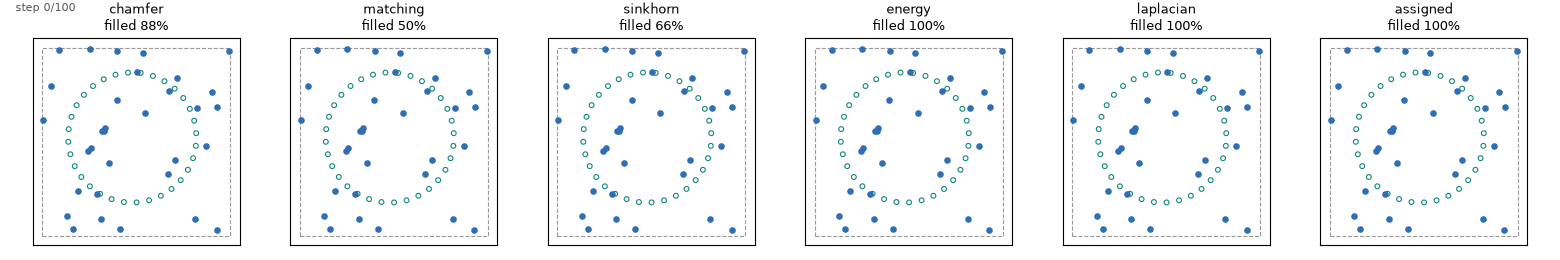

square, 16 drones


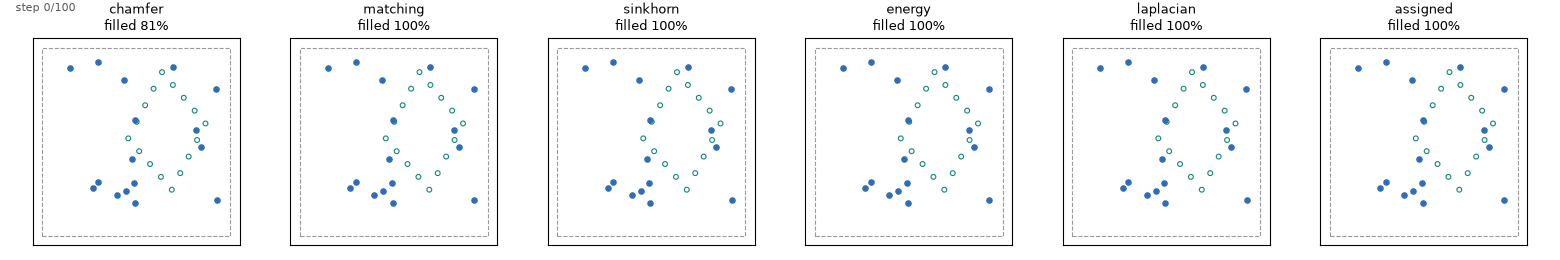

random polygon, 48 drones


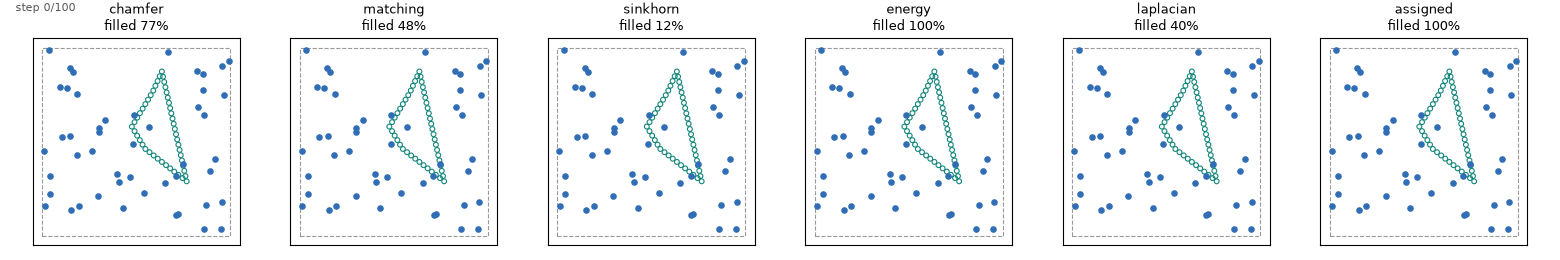

star, 32 drones


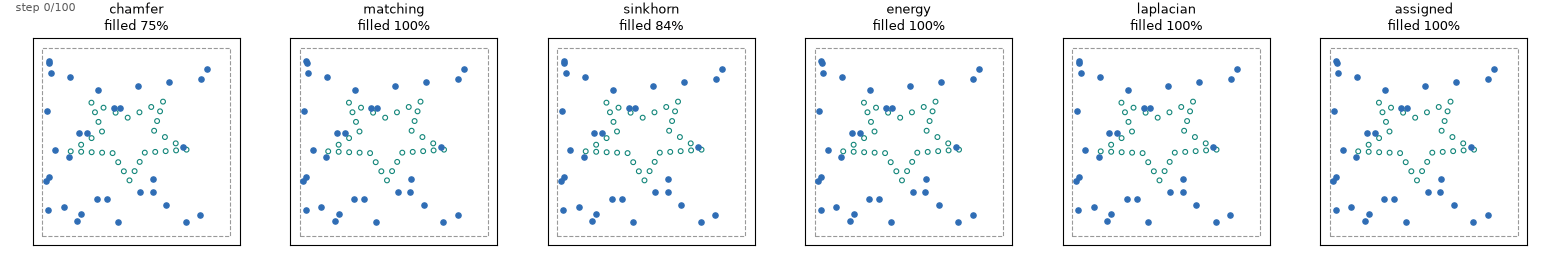

heart, 48 drones


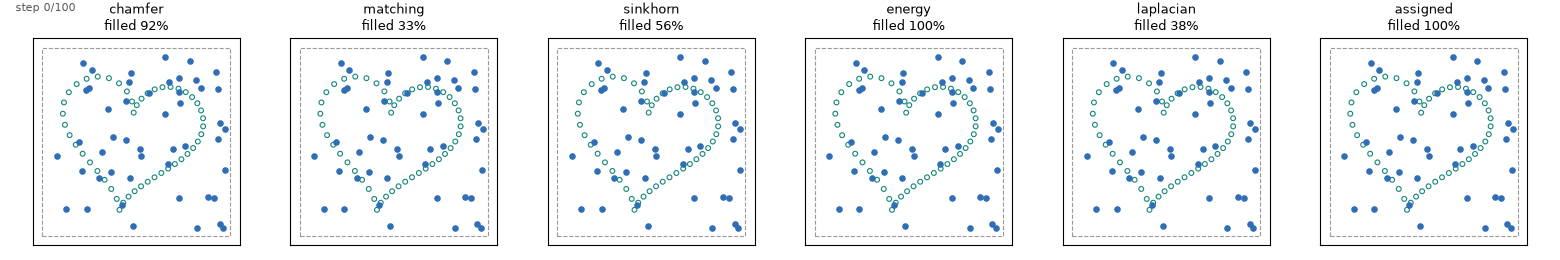

In [3]:
paths = []
for name, (p0, Q, dm) in SCENES.items():
    trajs = [results[(name, l)]["traj"] for l in LOSSES]
    titles = [f"{l}\nfilled {100 * results[(name, l)]['filled']:.0f}%" for l in LOSSES]
    slug = name.split(",")[0].replace(" ", "_")
    paths.append(viz.save_gif_grid(trajs, [Q[0]] * len(LOSSES), GIFS / f"phase1_losses_{slug}.gif",
                                   titles=titles, cols=len(LOSSES), panel=2.6))
for name, p in zip(SCENES, paths):
    print(name)
    display(Image(filename=p))

## 4. Average over the scenes

In [4]:
print(f"{'loss':11s}{'filled':>8s}{'slot err':>10s}{'close':>7s}")
for loss in LOSSES:
    r = [results[(name, loss)] for name in SCENES]
    print(f"{loss:11s}{100 * np.mean([x['filled'] for x in r]):7.0f}%{np.mean([x['err'] for x in r]):10.2f}"
          f"{np.mean([x['close'] for x in r]):7.1f}")

loss         filled  slot err  close
chamfer         82%      0.46    2.6
matching        66%      0.34    0.0
sinkhorn        64%      0.40    0.2
energy         100%      0.02    0.2
laplacian       75%      0.30    0.0
assigned       100%      0.01    0.0
